**Cosa fare**

1. misure lunghezza
2. prendere misure periodo a vaie lunghezze
3. confrontare periodo atteso e ottenuto

plottare in grafico lab per vedere legger di potenza , y=T e x =l

### Get data

In [7]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.optimize import curve_fit

In [8]:
periods = np.array([
[7.50, 7.55, 7.48, 7.47, 7.52, 7.51, 7.49, 7.40, 7.54, 7.58],
[8.63, 8.66, 8.67, 8.67, 8.67, 8.60, 8.62, 8.63, 8.68, 8.59],  
[9.59, 9.60, 9.64, 9.61, 9.61, 9.69, 9.60, 9.63, 9.64, 9.63],
[10.41, 10.56, 10.46, 10.40, 10.54, 10.44, 10.39, 10.39, 10.49, 10.45],
[11.21, 11.21, 11.21, 11.24, 11.18, 11.12, 11.25, 11.31, 11.23, 11.24],
[11.94, 11.97, 11.87, 12.02, 11.98, 11.89, 12.03, 11.90, 11.93, 11.94],
[12.61, 12.59, 12.59, 12.67, 12.59, 12.66, 12.64, 12.69, 12.71, 12.63],
[13.28, 13.33, 13.11, 13.24, 13.19, 13.23, 13.23, 13.26, 13.17, 13.20]
])

In [9]:
periods = np.array([[16.35, 16.36, 16.41, 16.34, 16.36],
              [15.77, 15.61, 15.78, 15.78, 15.74], #37
              [15.59, 15.61, 15.66, 15.62, 15.45],  #27              [16.67, 16.76, 16.59, 16.78, 16.60],
              [16.87, 16.44, 16.68, 16.54, 16.84], # 17
              [22.81, 22.85, 23.12, 22.87, 22.93],  #17
              [38.23, 38.82, 38.73, 38.99, 38.83],   #02
              [18.57, 18.83, 18.67, 18.90, 18.79],  # 
              [15.93, 15.76, 15.87, 15.94, 15.72],
              [15.73, 15.54, 15.47, 15.57, 15.65],
              [16.03, 15.97, 16.13, 16.19, 16.03]
              ])  

In [10]:
l = np.array([16.1, 20.9, 25.1, 29.4, 33.5, 37.8, 42.5, 45.6])

In [11]:
l = np.array([0.47, 0.37, 0.27, 0.17, 0.07, 0.02, 0.12, 0.22, 0.32, 0.42])


### Incertezze, elabora dati

In [12]:
sigma_l= np.full(l.shape, 0.5)

# Pay attention to the units: if l is in cm, sigma_l too
# or 0.3 ???

In [13]:
T = np.mean(periods, axis=1)/10
sigma_T = np.std(periods/10, ddof=1, axis=1)

### Stampa tabelle

In [14]:
for i in range(len(periods)):
    print(f'l: {l[i]:.2f}, T = {T[i]:.3f} + {sigma_T[i]:.3f}')

l: 0.47, T = 1.636 + 0.003
l: 0.37, T = 1.574 + 0.007
l: 0.27, T = 1.559 + 0.008
l: 0.17, T = 1.667 + 0.019
l: 0.07, T = 2.292 + 0.012
l: 0.02, T = 3.872 + 0.029
l: 0.12, T = 1.875 + 0.013
l: 0.22, T = 1.584 + 0.010
l: 0.32, T = 1.559 + 0.010
l: 0.42, T = 1.607 + 0.009


In [15]:
# Tabella piccola

for i in range(len(periods)):
    print(f'{l[i]:.2f} & {T[i]:.3f} & {sigma_T[i]:.3f} \\\\')

0.47 & 1.636 & 0.003 \\
0.37 & 1.574 & 0.007 \\
0.27 & 1.559 & 0.008 \\
0.17 & 1.667 & 0.019 \\
0.07 & 2.292 & 0.012 \\
0.02 & 3.872 & 0.029 \\
0.12 & 1.875 & 0.013 \\
0.22 & 1.584 & 0.010 \\
0.32 & 1.559 & 0.010 \\
0.42 & 1.607 & 0.009 \\


In [16]:
for i in range(len(periods)):
    formatted = ' & '.join(f'{value:.2f}' for value in periods[i])
    print(f'{l[i]:.2f} & {formatted} \\\\')

0.47 & 16.35 & 16.36 & 16.41 & 16.34 & 16.36 \\
0.37 & 15.77 & 15.61 & 15.78 & 15.78 & 15.74 \\
0.27 & 15.59 & 15.61 & 15.66 & 15.62 & 15.45 \\
0.17 & 16.87 & 16.44 & 16.68 & 16.54 & 16.84 \\
0.07 & 22.81 & 22.85 & 23.12 & 22.87 & 22.93 \\
0.02 & 38.23 & 38.82 & 38.73 & 38.99 & 38.83 \\
0.12 & 18.57 & 18.83 & 18.67 & 18.90 & 18.79 \\
0.22 & 15.93 & 15.76 & 15.87 & 15.94 & 15.72 \\
0.32 & 15.73 & 15.54 & 15.47 & 15.57 & 15.65 \\
0.42 & 16.03 & 15.97 & 16.13 & 16.19 & 16.03 \\


### With ODR

#### Fit

In [17]:
from scipy import odr

In [18]:
def power_law_odr(pars, x): # pars A,n
    # Note the independent variable is the last argument.
    return pars[0] * x ** pars[1]

In [19]:
def exponential_odr(pars, x):  # pars = [A, B]
    return pars[0] * np.exp(pars[1] * x)

In [20]:
x=np.array(l)
y=np.array(T)
sigma_x=np.array(sigma_l)
sigma_y=np.array(sigma_T)
fit_model=power_law_odr

In [21]:
model = odr.Model(fit_model)
data = odr.RealData(x, y, sx=sigma_x, sy=sigma_y)
alg = odr.ODR(data, model, beta0=(1.0, 1.0))
out = alg.run()

A_fit, n_fit = out.beta
sigma_A, sigma_n = np.sqrt(out.cov_beta.diagonal())
chisq_odr = out.sum_square

/tmp/ipykernel_10529/2654938180.py:3: RuntimeWarning: invalid value encountered in power
  return pars[0] * x ** pars[1]


In [22]:
print(f'A = {A_fit:.4f} + {sigma_A:.4f}\n',
      f'n = {n_fit:.4f} + {sigma_n:.4f}')

A = 1.1881 + 1.0693
 n = -0.2548 + 0.7505


In [23]:
print("Fitted parameters:", out.beta)
print("Parameter uncertainties:", out.sd_beta)

Fitted parameters: [ 1.18807086 -0.25479454]
Parameter uncertainties: [0.20967065 0.14716678]


#### Log graph

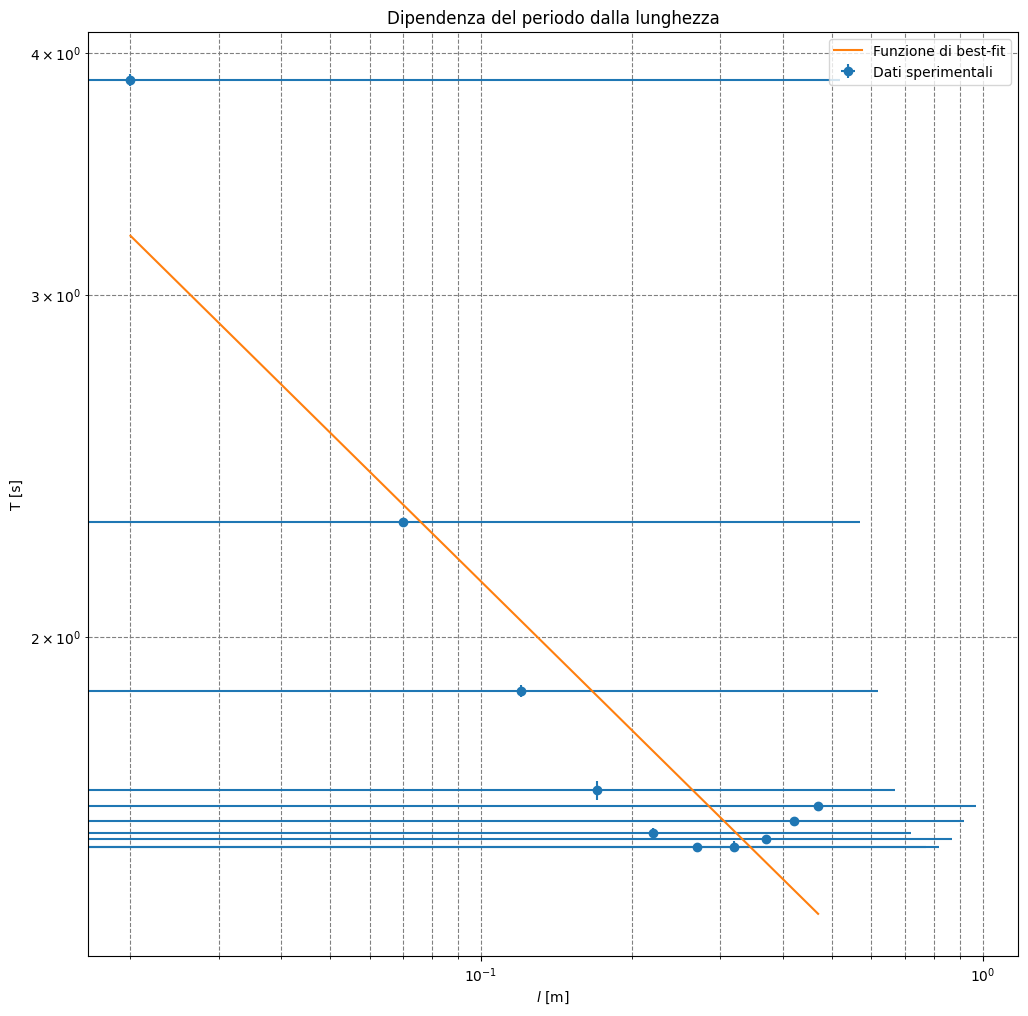

In [24]:
fig = plt.figure(figsize=(12, 12))

t = np.linspace(x.min(), x.max(), 1000)
plt.errorbar(x,y, xerr=sigma_x, yerr=sigma_y, fmt='o', label='Dati sperimentali')
plt.plot(t, power_law_odr(out.beta, t), label='Funzione di best-fit')

plt.xscale('log')   # if exponential in semi-log, DO NOT PUT THIS LINE
plt.yscale('log')

plt.title('Dipendenza del periodo dalla lunghezza')
plt.xlabel('$l$ [m]')
plt.ylabel('T [s]')
plt.legend()
plt.grid(which='both', ls='dashed', color='gray')

plt.show()


#### Chi square

In [25]:
# Chi square

y_model = fit_model(out.beta, x)
chi2_manual = np.sum(((y - y_model) / sigma_y)**2)

dof = len(y) - len(out.beta)


print(f'Propagating errors on x: {chisq_odr}')
print(f'Ignoring errors on x: {chi2_manual}')
print(f'DOF: {dof}')

Propagating errors on x: 0.3076012419856119
Ignoring errors on x: 6739.261193754855
DOF: 8


In [26]:
from scipy.stats import chi2

dof = 6
p_value = chi2.sf(chisq_odr, dof)  # maybe put manual?
print(f"P-value: {p_value}")

P-value: 0.9994594682447995


### With scipy

#### Fit

just to check it's the same

In [27]:
def power_law(x, norm, index):
    """Modello di tipo legge di potenza"""
    return norm * (x**index)

In [28]:
model=power_law

x=np.array(l)
y=np.array(T)
sigma_x=np.array(sigma_l)
sigma_y=np.array(sigma_T)

In [29]:
popt, pcov = curve_fit(power_law, x,y)
norm_hat, index_hat = popt
sigma_norm, sigma_index = np.sqrt(pcov.diagonal())

In [30]:
print(f'A = {norm_hat:.4f} + {sigma_norm:.4f}\n',
      f'n = {index_hat:.4f} + {sigma_index:.4f}')

A = 1.0531 + 0.0751
 n = -0.3216 + 0.0263


#### Log graph

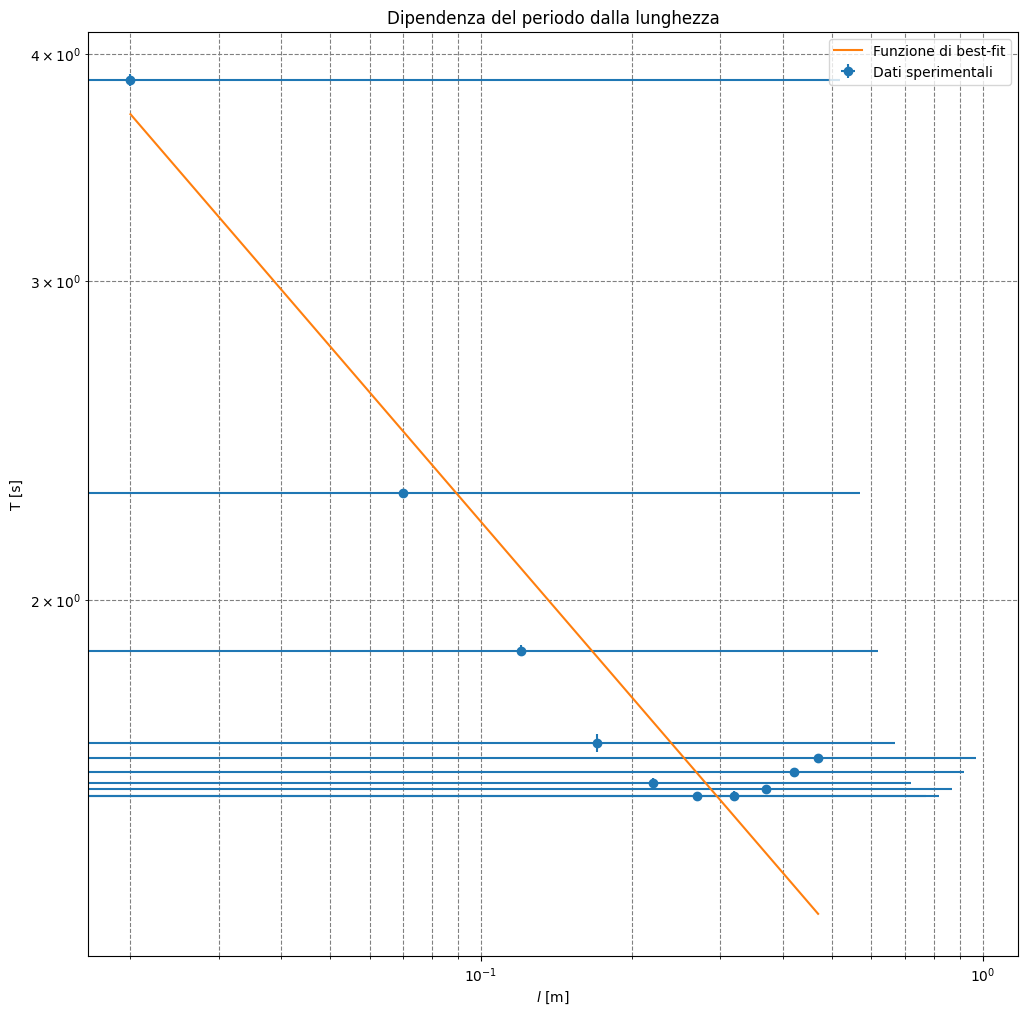

In [31]:
fig = plt.figure(figsize=(12, 12))

t = np.linspace(x.min(), x.max(), 1000)
plt.errorbar(x,y, xerr=sigma_x, yerr=sigma_y, fmt='o', label='Dati sperimentali')
plt.plot(t, power_law(t, norm_hat, index_hat), label='Funzione di best-fit')

plt.xscale('log')   # if exponential in semi-log, DO NOT PUT THIS LINE
plt.yscale('log')

plt.title('Dipendenza del periodo dalla lunghezza')
plt.xlabel('$l$ [m]')
plt.ylabel('T [s]')
plt.legend()

plt.grid(which='both', ls='dashed', color='gray')

plt.show()


#### Chi quadro e p-value

In [32]:
res = y - model(x, *popt)

In [33]:
chisq = np.sum((res / sigma_y)**2)
dof = len(y) - len(popt)
chi2_red = chisq / dof  # must give 1  

print(f'Chi: {chisq}')
print(f'Dof: {dof}')
print(f'Chi reduced: {chi2_red}')

Chi: 13554.036515731743
Dof: 8
Chi reduced: 1694.2545644664679


In [34]:
p_value = chi2.sf(chisq, dof)
print(f"P-value: {p_value}")

P-value: 0.0


### Other Graph

In [35]:
def period_model(l):
    return 2.0 * np.pi * np.sqrt(l / (9.81))

In [36]:
x_lim = max(x)+1
xgrid = np.linspace(0.0, x_lim, 100)
y2 = period_model(xgrid)
y3_odr = power_law_odr(out.beta, xgrid)  # pars A,n
y3_scipy = power_law(xgrid, *popt)

/tmp/ipykernel_10529/2654938180.py:3: RuntimeWarning: divide by zero encountered in power
  return pars[0] * x ** pars[1]


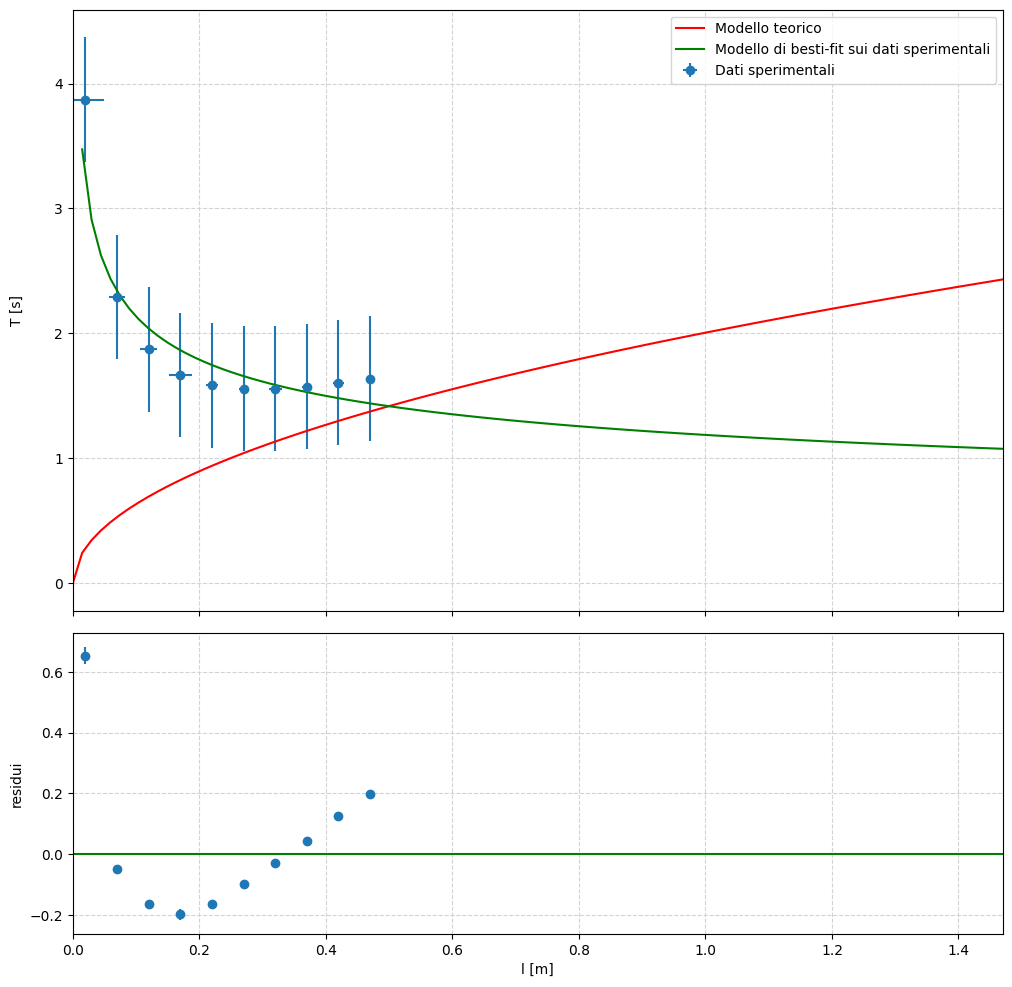

In [37]:
### ODR

# Create the main figure
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))

ax1.errorbar(x, y, sigma_x, sigma_y, fmt='o', label='Dati sperimentali')
ax1.plot(xgrid, y2, label = 'Modello teorico', c='red')  # could not put it at all
ax1.plot(xgrid, y3_odr, label = 'Modello di besti-fit sui dati sperimentali', c='green')

res_odr = y- power_law_odr(out.beta, x)  # pars A,n

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res_odr, sigma_y, fmt='o')     # put res to have the other residuals, referring to the other line
ax2.plot(xgrid, np.full(xgrid.shape, 0.0), c='green') # horizontal line at y=0

# STYLING  

ax1.set_ylabel('T [s]')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

ax2.set_xlabel('l [m]')
ax2.set_ylabel('residui')
ax2.grid(color='lightgray', ls='dashed')

plt.xlim(0.0, x_lim)
fig.align_ylabels((ax1, ax2))

plt.show()

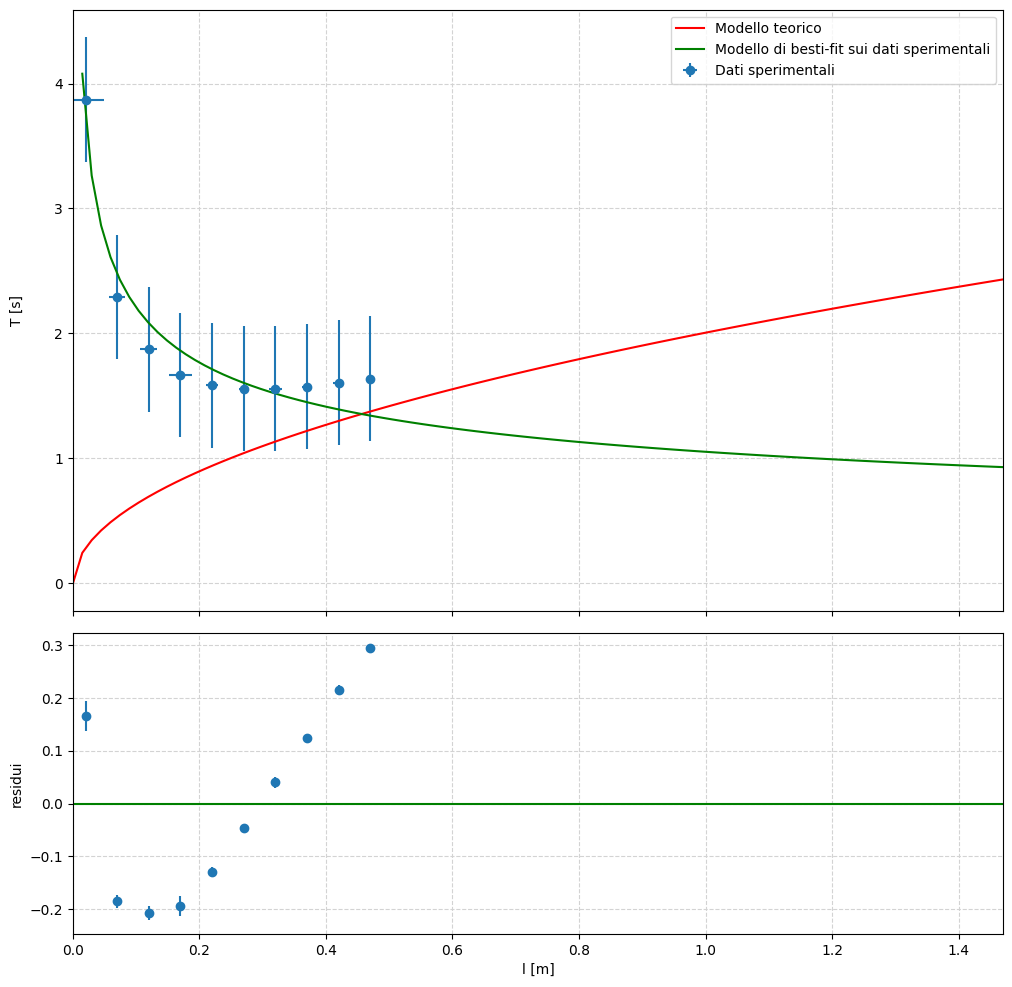

In [38]:
### SCIPY


# Create the main figure
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))

ax1.errorbar(x, y, sigma_x, sigma_y, fmt='o', label='Dati sperimentali')
ax1.plot(xgrid, y2, label = 'Modello teorico', c='red')
ax1.plot(xgrid, y3_scipy, label = 'Modello di besti-fit sui dati sperimentali', c='green')

res_scipy = y - power_law(x, *popt)

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res_scipy, sigma_y, fmt='o')     # put res to have the other residuals, referring to the other line
ax2.plot(xgrid, np.full(xgrid.shape, 0.0), c='green') # horizontal line at y=0

# STYLING  

ax1.set_ylabel('T [s]')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

ax2.set_xlabel('l [m]')
ax2.set_ylabel('residui')
ax2.grid(color='lightgray', ls='dashed')

plt.xlim(0.0, x_lim)
fig.align_ylabels((ax1, ax2))

plt.show()